
# Task 2: California Housing Price Prediction

## Objective
To build a Machine Learning model that predicts house prices using the California Housing dataset.

## Dataset
California Housing Dataset

## Target Variable
median_house_value

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn


Libraries imported successfully!
Dataset loaded successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
Dataset Shape

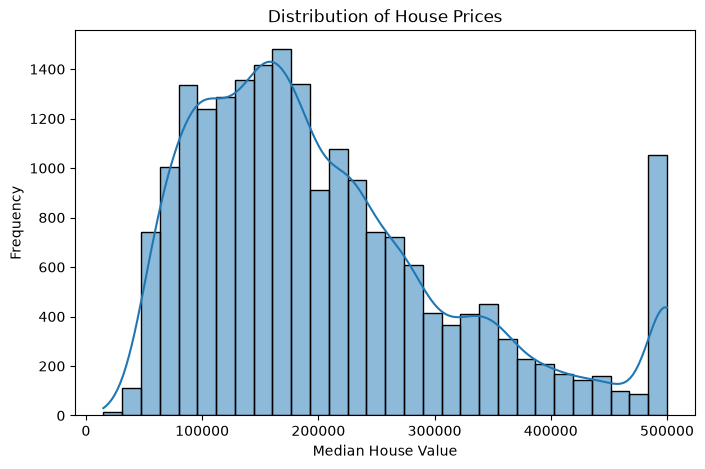

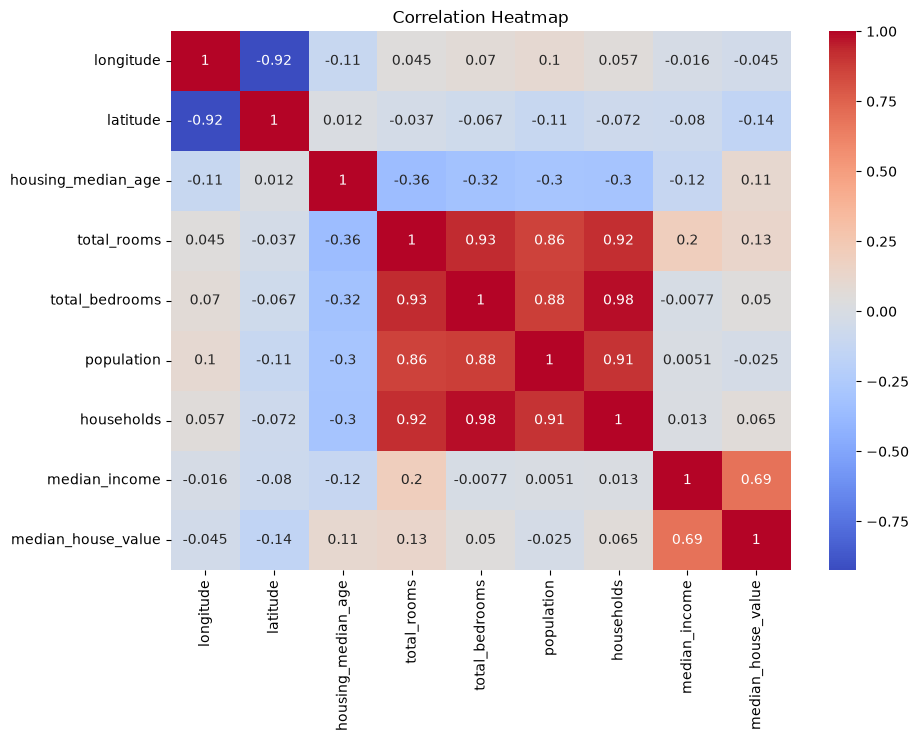

Features:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity'],
      dtype='str')

Target Variable: median_house_value
Training Data: (16346, 9)
Testing Data: (4087, 9)
Categorical columns encoded successfully!
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  ocean_proximity_INLAND  \
0       322.0       126.0         8.3252                   False   
1      2401.0      1138.0         8.3014                   False   
2       496.0       1

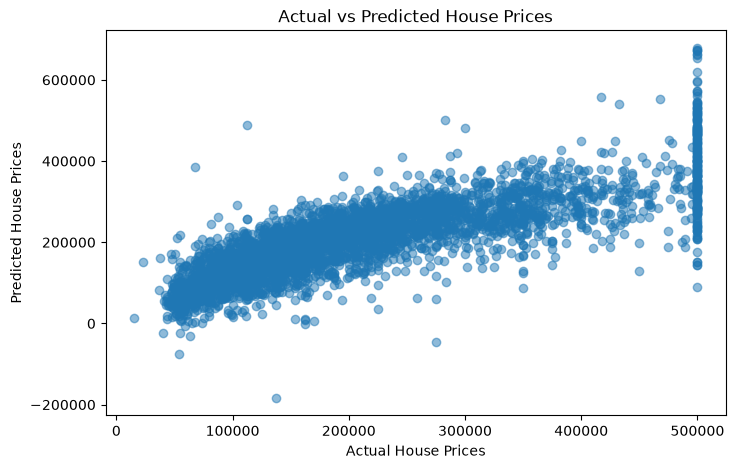

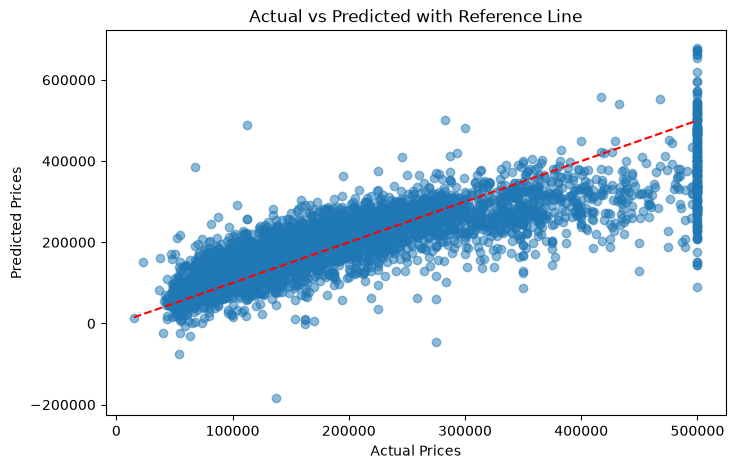

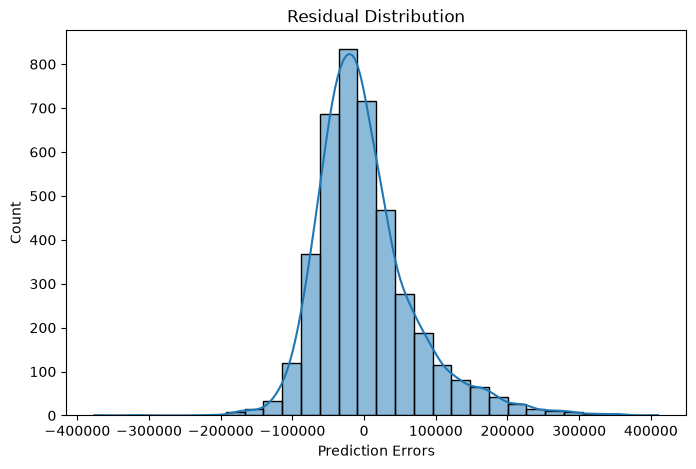

                       Feature    Coefficient
9       ocean_proximity_ISLAND  213653.374463
7                median_income   39277.083020
11  ocean_proximity_NEAR OCEAN    3166.477128
2           housing_median_age    1081.364206
4               total_bedrooms     103.004042
6                   households      43.142725
3                  total_rooms      -6.322146
5                   population     -36.409751
10    ocean_proximity_NEAR BAY   -6232.416876
1                     latitude  -25657.807543
0                    longitude  -27108.746321
8       ocean_proximity_INLAND  -39240.217778
CALIFORNIA HOUSING PRICE PREDICTION
-----------------------------------
Model: Linear Regression
MAE: 50413.43
RMSE: 69297.72
R2 Score: 0.6488

Project Completed Successfully!


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print(df.head())

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

df = df.dropna()

print("Missing values after cleaning:")
print(df.isnull().sum())

plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

print("Features:")
print(X.columns)

print("\nTarget Variable: median_house_value")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

X = pd.get_dummies(X, drop_first=True)

print("Categorical columns encoded successfully!")
print(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

model = LinearRegression()

print("Linear Regression model created successfully!")

model.fit(X_train, y_train)

print("Model trained successfully!")

y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted with Reference Line")
plt.show()

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Errors")
plt.show()

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(feature_importance.sort_values(
    by='Coefficient', ascending=False
))

print("CALIFORNIA HOUSING PRICE PREDICTION")
print("-----------------------------------")
print("Model: Linear Regression")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("\nProject Completed Successfully!")
